In [8]:
results_dir = "/projectnb/vkolagrp/ketanss/adrd_agent_custom/adrd_agent/DiscoAD_MAS/results"

points = {
    2: [],
    3: []
}

import pandas as pd
for keyword in range(2, 4):
    path = results_dir + f"/{keyword}_keywords.csv"
    df = pd.read_csv(path)
    points[keyword] = df.groupby('run_number')['hypothesis_approved'].mean()

points[2] = pd.read_csv("/projectnb/vkolagrp/ketanss/adrd_agent_custom/adrd_agent/DiscoAD_MAS/results/hypothesis_approval_tracking_20250921_141256.csv").groupby('run_number')['hypothesis_approved'].mean()
points[3] = pd.read_csv("/projectnb/vkolagrp/ketanss/adrd_agent_custom/adrd_agent/DiscoAD_MAS/results/hypothesis_approval_tracking_20250922_032811.csv").groupby('run_number')['hypothesis_approved'].mean()

Approval rates by run (2 keywords):
run_number
1      0.500000
2      0.250000
3      0.333333
4      0.000000
5      0.333333
         ...   
296    0.000000
297    0.666667
298    0.000000
299    0.333333
300    0.750000
Name: hypothesis_approved, Length: 300, dtype: float64

Approval rates by run (3 keywords):
run_number
1      0.800000
2      1.000000
3      0.600000
4      0.400000
5      0.400000
         ...   
108    0.200000
109    0.500000
110    0.333333
111    0.400000
112    0.000000
Name: hypothesis_approved, Length: 112, dtype: float64


/scratch/ipykernel_3551674/2332497210.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_plot = plt.boxplot(data, patch_artist=True,


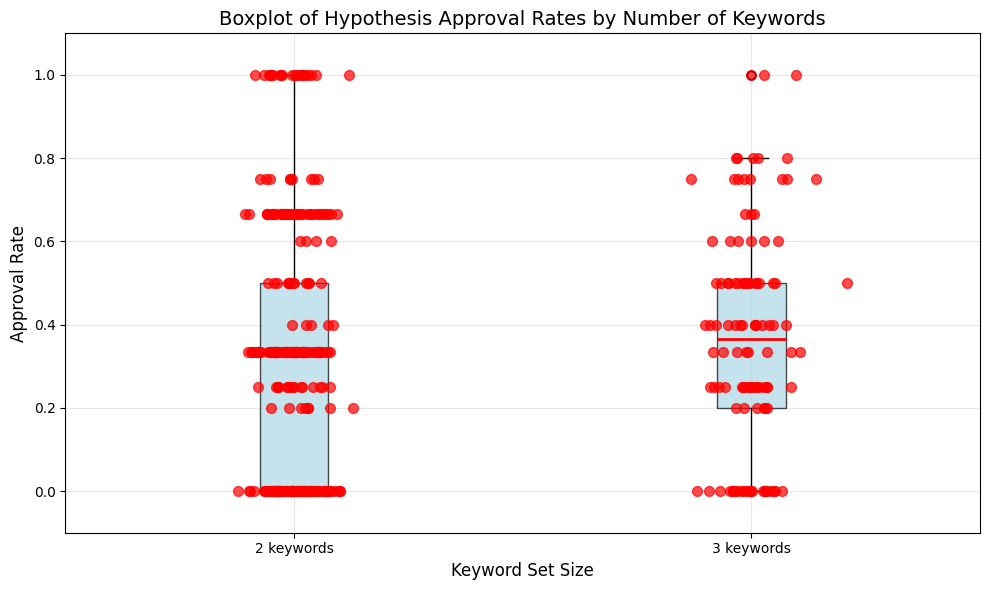

In [9]:
# Show the data for both 2-keyword and 3-keyword runs
import matplotlib.pyplot as plt
import numpy as np

print("Approval rates by run (2 keywords):")
print(points[2])
print("\nApproval rates by run (3 keywords):")
print(points[3])

# Prepare data for boxplot: list of arrays, one for each keyword count
data = [points[2].values, points[3].values]
labels = ['2 keywords', '3 keywords']

plt.figure(figsize=(10, 6))

# Create boxplot
box_plot = plt.boxplot(data, patch_artist=True, 
                       boxprops=dict(facecolor='lightblue', alpha=0.7),
                       medianprops=dict(color='red', linewidth=2),
                       labels=labels)

# Add individual data points as dots for each group
for i, y_values in enumerate(data):
    x_values = np.full_like(y_values, i+1, dtype=float)
    jitter = np.random.normal(0, 0.05, len(y_values))
    x_values += jitter
    plt.scatter(x_values, y_values, color='red', s=50, alpha=0.7, zorder=3)

# Customize the plot
plt.title('Boxplot of Hypothesis Approval Rates by Number of Keywords', fontsize=14)
plt.ylabel('Approval Rate', fontsize=12)
plt.xlabel('Keyword Set Size', fontsize=12)
plt.xticks([1, 2], labels)
plt.grid(True, alpha=0.3)
plt.ylim(-0.1, 1.1)

plt.tight_layout()
plt.show()


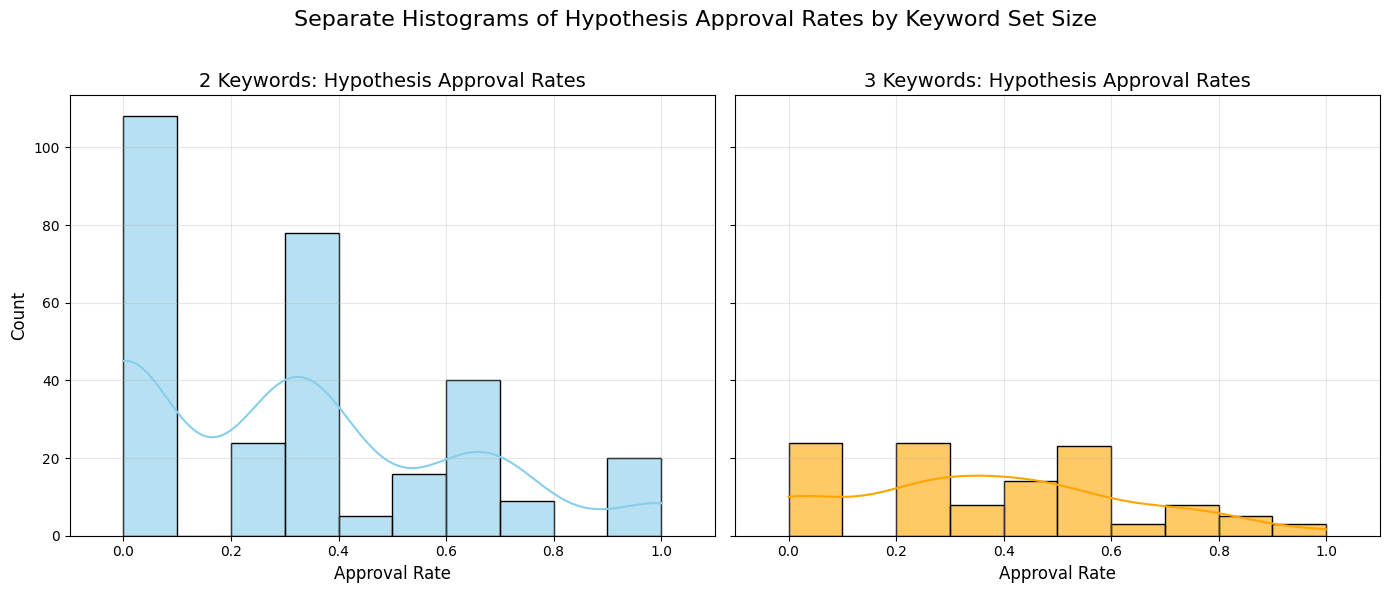

In [11]:
# Plot two separate histograms (with KDE) for 2-keyword and 3-keyword approval rates

import seaborn as sns
import pandas as pd

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# 2-keyword histogram
sns.histplot(
    points[2].values,
    kde=True,
    bins=10,
    color='skyblue',
    alpha=0.6,
    edgecolor='black',
    ax=axes[0]
)
axes[0].set_title('2 Keywords: Hypothesis Approval Rates', fontsize=14)
axes[0].set_xlabel('Approval Rate', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)
axes[0].set_xlim(-0.1, 1.1)
axes[0].grid(True, alpha=0.3)

# 3-keyword histogram
sns.histplot(
    points[3].values,
    kde=True,
    bins=10,
    color='orange',
    alpha=0.6,
    edgecolor='black',
    ax=axes[1]
)
axes[1].set_title('3 Keywords: Hypothesis Approval Rates', fontsize=14)
axes[1].set_xlabel('Approval Rate', fontsize=12)
axes[1].set_ylabel('')  # No y-label for right plot
axes[1].set_xlim(-0.1, 1.1)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Separate Histograms of Hypothesis Approval Rates by Keyword Set Size', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

np.random.seed(42)

# --- Simulate data for original two plots ---
unique_keywords = [2, 3, 4, 5, 6, 8]
unique_outer_turns = [1, 2, 3, 4]
unique_hypotheses = [3, 4, 5, 6]

data = []
for kw in unique_keywords:
    for ot in unique_outer_turns:
        for hyp in unique_hypotheses:
            base_approval = 0.8 - 0.1 * (kw - 2) - 0.07 * (hyp - 3)
            group_approval = base_approval + 0.08 * (ot - 1)
            for _ in range(6):
                approval = np.clip(np.random.normal(group_approval, 0.07), 0, 1)
                data.append({
                    'keywords': kw,
                    'outer_turns': ot,
                    'hypotheses': hyp,
                    'approval_rate': approval
                })
df_approval = pd.DataFrame(data)

# --- Simulate data for Data Prep Agent plot ---
n_points = 30
prep_agent = np.array([0]*n_points + [1]*n_points)
approval_rate_prep = np.concatenate([
    np.clip(np.random.normal(0.68, 0.08, n_points), 0, 1),  # Without agent
    np.clip(np.random.normal(0.81, 0.07, n_points), 0, 1)   # With agent
])
df_prep = pd.DataFrame({
    "prep_agent": prep_agent,
    "approval_rate": approval_rate_prep
})

# --- Simulate data for LLM size and number of datasets (combined) ---
llm_sizes = ["7B", "13B", "34B", "70B"]
llm_size_numeric = [7, 13, 34, 70]
num_datasets = [1, 2, 3, 4, 5]

# Simulate approval rates for each (llm_size, num_datasets) combination
llm_base = [0.68, 0.74, 0.80, 0.83]
llm_std = [0.04, 0.03, 0.025, 0.02]
dataset_increments = [0.0, 0.03, 0.06, 0.09, 0.12]  # Each dataset adds a boost

llm_dataset_data = []
for i, (llm, llm_num, base, std) in enumerate(zip(llm_sizes, llm_size_numeric, llm_base, llm_std)):
    for j, ds in enumerate(num_datasets):
        mean = base + dataset_increments[j]
        for _ in range(10):
            approval = np.clip(np.random.normal(mean, std), 0, 1)
            llm_dataset_data.append({
                "llm_size": llm,
                "llm_size_num": llm_num,
                "num_datasets": ds,
                "approval_rate": approval
            })
df_llm_dataset = pd.DataFrame(llm_dataset_data)

# --- Plotting ---
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# --- Plot 1: Approval Rate vs Number of Keywords (Outer Turns as parameter) ---
ax = axes[0, 0]
boxplot_data = []
positions = []
width = 0.5
for i, kw in enumerate(unique_keywords):
    for j, ot in enumerate(unique_outer_turns):
        group = df_approval[(df_approval['keywords'] == kw) & (df_approval['outer_turns'] == ot)]
        if not group.empty:
            boxplot_data.append(group['approval_rate'].values)
            pos = i + (j - len(unique_outer_turns)/2) * width / len(unique_outer_turns)
            positions.append(pos)
ax.boxplot(boxplot_data, positions=positions, widths=width/len(unique_outer_turns), patch_artist=True)
ax.set_xlabel('Number of Keywords (T=Outer Turns)')
ax.set_ylabel('Approval Rate')
ax.set_title('Approval Rate vs Number of Keywords\n(Outer Turns as color)')
ax.set_xticks([i for i in range(len(unique_keywords))])
ax.set_xticklabels([str(kw) for kw in unique_keywords])
legend_handles = [Patch(facecolor='white', edgecolor='black', label=f'Outer Turns {ot}') for ot in unique_outer_turns]
ax.legend(handles=legend_handles, title='Outer Turns', loc='upper right')

# --- Plot 2: Approval Rate vs Number of Hypotheses (Keywords as parameter) ---
ax = axes[0, 1]
boxplot_data = []
positions = []
width = 0.5
for i, hyp in enumerate(unique_hypotheses):
    for j, kw in enumerate(unique_keywords):
        group = df_approval[(df_approval['hypotheses'] == hyp) & (df_approval['keywords'] == kw)]
        if not group.empty:
            boxplot_data.append(group['approval_rate'].values)
            pos = i + (j - len(unique_keywords)/2) * width / len(unique_keywords)
            positions.append(pos)
ax.boxplot(boxplot_data, positions=positions, widths=width/len(unique_keywords), patch_artist=True)
ax.set_xlabel('Number of Hypotheses (K=Keywords)')
ax.set_ylabel('Approval Rate')
ax.set_title('Approval Rate vs Number of Hypotheses\n(Keywords as color)')
ax.set_xticks([i for i in range(len(unique_hypotheses))])
ax.set_xticklabels([str(hyp) for hyp in unique_hypotheses])
legend_handles = [Patch(facecolor='white', edgecolor='black', label=f'Keywords {kw}') for kw in unique_keywords]
ax.legend(handles=legend_handles, title='Keywords', loc='upper right')

# --- Plot 3: Approval Rate with and without Data Prep Agent ---
ax = axes[1, 0]
prep_labels = ['No Data Prep Agent', 'With Data Prep Agent']
box_data = [df_prep[df_prep['prep_agent']==0]['approval_rate'],
            df_prep[df_prep['prep_agent']==1]['approval_rate']]
ax.boxplot(box_data, patch_artist=True, labels=prep_labels)
ax.set_ylabel('Approval Rate')
ax.set_title('Approval Rate With vs Without Data Prep Agent')
ax.set_ylim(0, 1)

# --- Plot 4: Approval Rate vs LLM Size grouped by Number of Datasets ---
ax = axes[1, 1]
colors = plt.cm.viridis(np.linspace(0, 1, len(num_datasets)))
for idx, ds in enumerate(num_datasets):
    group = df_llm_dataset[df_llm_dataset['num_datasets'] == ds]
    means = group.groupby('llm_size_num')['approval_rate'].mean().reindex(llm_size_numeric)
    stds = group.groupby('llm_size_num')['approval_rate'].std().reindex(llm_size_numeric)
    ax.errorbar(llm_size_numeric, means, yerr=stds, fmt='-o', label=f'{ds} dataset{"s" if ds > 1 else ""}', color=colors[idx])
ax.set_xlabel('LLM Size (Billion Params)')
ax.set_ylabel('Approval Rate')
ax.set_xticks(llm_size_numeric)
ax.set_xticklabels(llm_sizes)
ax.set_title('Approval Rate vs LLM Size\nGrouped by Number of Datasets')
ax.legend(title='Num Datasets', loc='lower right')

plt.tight_layout()
plt.show()


: 